STATISTICAL ANALYSIS OF WORLD HAPPINESS
Dataset shape: (1002, 11)
Period analysed: 2011–2017
Country-year observations: 1002

HAPPINESS SCORE SUMMARY
count    1002.000000
mean        5.416742
std         1.130385
min         2.662000
25%         4.571500
50%         5.343500
75%         6.235500
max         7.788000
Name: Ladder score, dtype: float64
Mean: 5.42
Median: 5.34
Standard deviation: 1.13
Skewness: 0.058


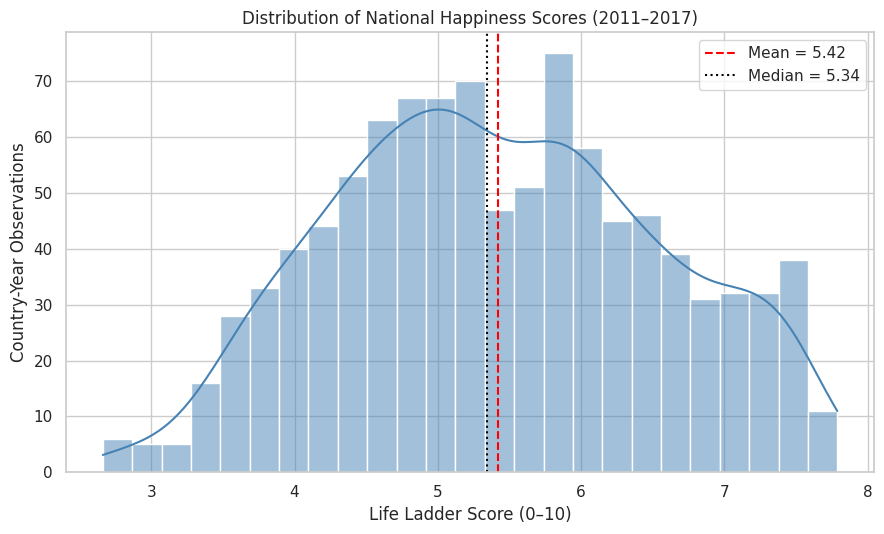

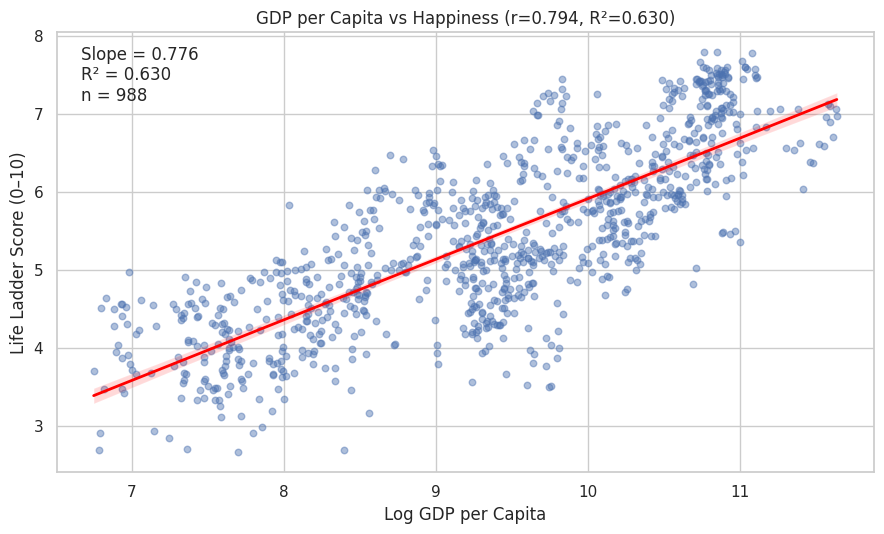


GDP AND HAPPINESS REGRESSION
Slope: 0.776
Pearson correlation: 0.794
R-squared: 0.63
Complete observations: 988


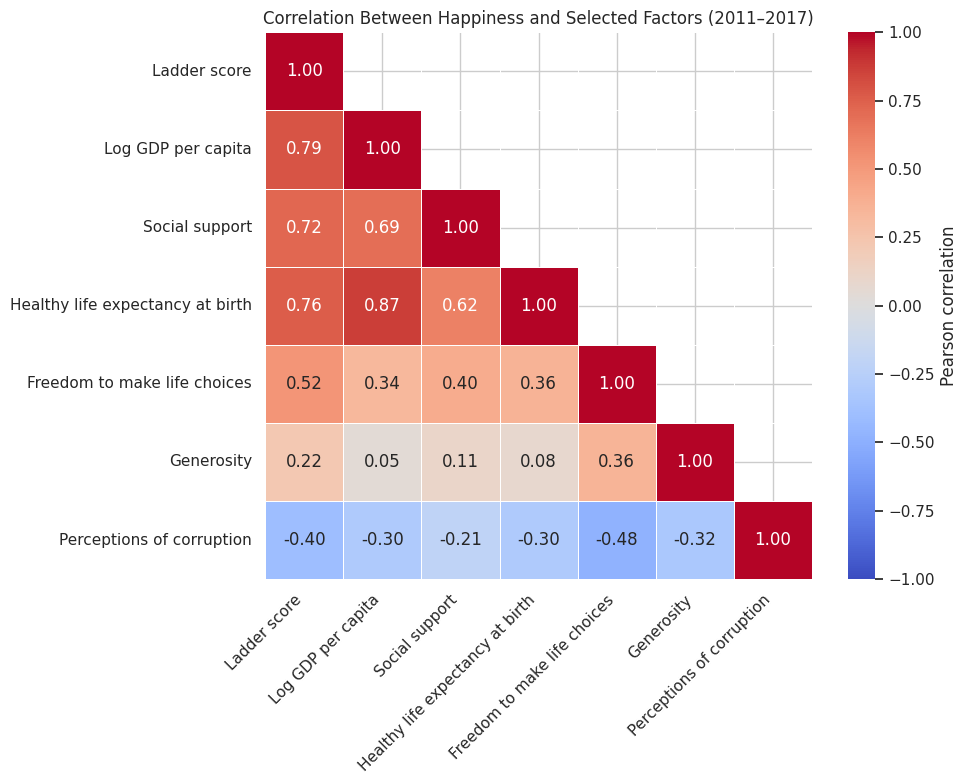


CORRELATION WITH HAPPINESS
Ladder score                        1.000000
Log GDP per capita                  0.794231
Healthy life expectancy at birth    0.764577
Social support                      0.718988
Freedom to make life choices        0.518027
Generosity                          0.223122
Perceptions of corruption          -0.404945
Name: Ladder score, dtype: float64

CORRELATION MATRIX


,Ladder score,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption
Ladder score,1.00,0.79,0.72,0.76,0.52,0.22,-0.40
Log GDP per capita,0.79,1.00,0.69,0.87,0.34,0.05,-0.30
Social support,0.72,0.69,1.00,0.62,0.40,0.11,-0.21
Healthy life expectancy at birth,0.76,0.87,0.62,1.00,0.36,0.08,-0.30
Freedom to make life choices,0.52,0.34,0.40,0.36,1.00,0.36,-0.48
Generosity,0.22,0.05,0.11,0.08,0.36,1.00,-0.32
Perceptions of corruption,-0.40,-0.30,-0.21,-0.30,-0.48,-0.32,1.00



ANALYSIS COMPLETED: ALL THREE FIGURES GENERATED.


In [5]:
!pip -q install pandas numpy matplotlib seaborn scipy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress, skew
from IPython.display import display

# LOAD DATASET

url = "https://raw.githubusercontent.com/VStanys/CSV-WHR/main/world-happiness-report.csv"

df = pd.read_csv(url)
df.columns = df.columns.str.strip()

df["year"] = pd.to_numeric(df["year"], errors="coerce")
data = df[df["year"].between(2011, 2017)].copy()

columns = [
    "Ladder score",
    "Log GDP per capita",
    "Social support",
    "Healthy life expectancy at birth",
    "Freedom to make life choices",
    "Generosity",
    "Perceptions of corruption"
]

for col in columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

sns.set_theme(style="whitegrid")

print("STATISTICAL ANALYSIS OF WORLD HAPPINESS")
print("=" * 55)
print("Dataset shape:", data.shape)
print("Period analysed: 2011–2017")
print("Country-year observations:", data["Ladder score"].count())


# DESCRIPTIVE STATISTICS

happiness = data["Ladder score"].dropna()

mean_score = happiness.mean()
median_score = happiness.median()

print("\nHAPPINESS SCORE SUMMARY")
print(happiness.describe())
print("Mean:", round(mean_score, 2))
print("Median:", round(median_score, 2))
print("Standard deviation:", round(happiness.std(), 2))
print("Skewness:", round(skew(happiness), 3))


# FIGURE 1: DISTRIBUTION OF HAPPINESS SCORES

fig, ax = plt.subplots(figsize=(9, 5.5))

sns.histplot(
    happiness,
    bins=25,
    kde=True,
    color="steelblue",
    edgecolor="white",
    ax=ax
)

ax.axvline(
    mean_score,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {mean_score:.2f}"
)

ax.axvline(
    median_score,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label=f"Median = {median_score:.2f}"
)

ax.set_title("Distribution of National Happiness Scores (2011–2017)")
ax.set_xlabel("Life Ladder Score (0–10)")
ax.set_ylabel("Country-Year Observations")
ax.legend()

plt.tight_layout()
plt.show()


# FIGURE 2: GDP PER CAPITA VS HAPPINESS

scatter_data = data[
    ["Log GDP per capita", "Ladder score"]
].dropna()

x = scatter_data["Log GDP per capita"]
y = scatter_data["Ladder score"]

regression = linregress(x, y)

r = regression.rvalue
r_squared = r ** 2
slope = regression.slope

fig, ax = plt.subplots(figsize=(9, 5.5))

sns.regplot(
    data=scatter_data,
    x="Log GDP per capita",
    y="Ladder score",
    scatter_kws={"alpha": 0.45, "s": 22},
    line_kws={"color": "red", "linewidth": 2},
    ax=ax
)

ax.set_title(
    f"GDP per Capita vs Happiness (r={r:.3f}, R²={r_squared:.3f})"
)

ax.set_xlabel("Log GDP per Capita")
ax.set_ylabel("Life Ladder Score (0–10)")

ax.text(
    0.03, 0.97,
    f"Slope = {slope:.3f}\nR² = {r_squared:.3f}\nn = {len(scatter_data)}",
    transform=ax.transAxes,
    va="top"
)

plt.tight_layout()
plt.show()

print("\nGDP AND HAPPINESS REGRESSION")
print("Slope:", round(slope, 3))
print("Pearson correlation:", round(r, 3))
print("R-squared:", round(r_squared, 3))
print("Complete observations:", len(scatter_data))


# FIGURE 3: TRIANGULAR CORRELATION HEATMAP

correlation_data = data[columns].dropna()

corr = correlation_data.corr(method="pearson")

# Hide upper triangle, retain diagonal and lower triangle
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax
)

ax.set_title(
    "Correlation Between Happiness and Selected Factors (2011–2017)"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


# FINAL STATISTICAL OUTPUTS

print("\nCORRELATION WITH HAPPINESS")
print(corr["Ladder score"].sort_values(ascending=False))

print("\nCORRELATION MATRIX")
display(corr.round(2))

print("\nANALYSIS COMPLETED: ALL THREE FIGURES GENERATED.")